In [2]:
import pandas as pd
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt

In [19]:
(x_train,_),(x_test,_) = mnist.load_data()

x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

x_train = np.expand_dims(x_train,-1)
x_test = np.expand_dims(x_test,-1)

x_train.shape

(60000, 28, 28)


(60000, 28, 28, 1)

In [9]:
noisy_factor = 0.3
x_train_noisy = np.clip(x_train + noisy_factor * np.random.randn(*x_train.shape),0.,1.)
x_test_noisy = np.clip(x_test + noisy_factor * np.random.randn(*x_test.shape),0.,1.)



In [24]:
input_img = layers.Input((28,28,1))
x = layers.Conv2D(32,(3,3),padding='same',activation='relu')(input_img)
x = layers.MaxPooling2D((2,2),padding='same')(x)
x = layers.Conv2D(32,(3,3),padding='same',activation='relu')(x)
encoded = layers.MaxPooling2D((2,2),padding='same')(x)
x = layers.Conv2D(32,(3,3),padding='same',activation='relu')(encoded)
x = layers.UpSampling2D((2,2))(x)
x = layers.Conv2D(32,(3,3),padding='same',activation='relu')(x)
x = layers.UpSampling2D((2,2))(x)
decoded = layers.Conv2D(1,(3,3),padding='same',activation='sigmoid')(x)

autoencoder = models.Model(input_img,decoded)

autoencoder.compile(loss='binary_crossentropy',optimizer='adam')

history = autoencoder.fit(
    x_train_noisy,
    x_train,
    validation_data = (x_test_noisy,x_test),
    epochs = 2,
    batch_size = 128,
    shuffle = True
)

Epoch 1/2
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - loss: 0.1392 - val_loss: 0.0916
Epoch 2/2
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - loss: 0.0894 - val_loss: 0.0859


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


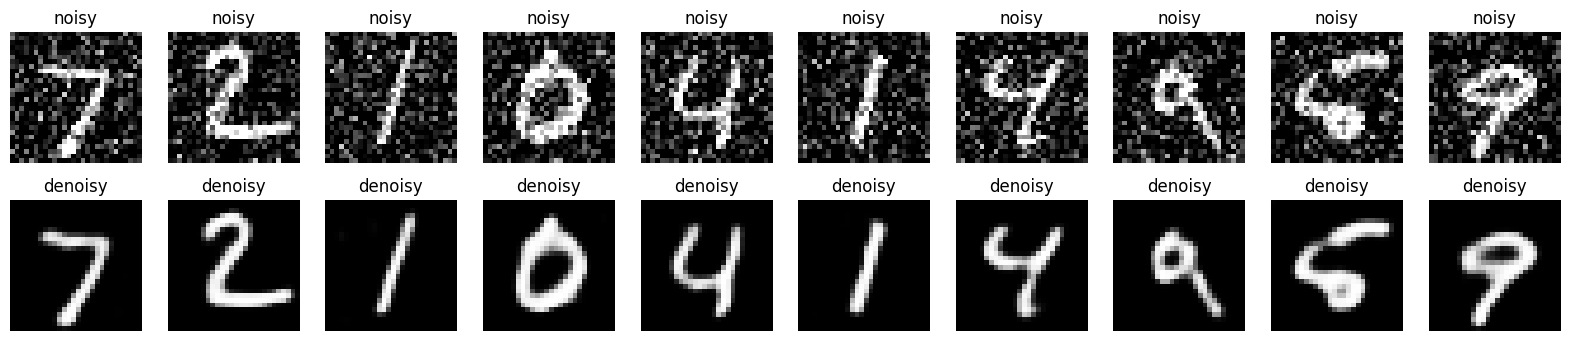

In [16]:
predicted = autoencoder.predict(x_test_noisy)

plt.figure(figsize=(20,4))
n=10
for i in range(n):
    ax = plt.subplot(2,n,i+1)
    plt.imshow(x_test_noisy[i].reshape(28,28),cmap='gray')
    plt.title("noisy")
    plt.axis("off")

    ax = plt.subplot(2,n,i+1+n)
    plt.imshow(predicted[i].reshape(28,28),cmap='gray')
    plt.title("denoisy")
    plt.axis("off")
plt.show()